In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import joblib
import json
import time
import os
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

device = torch.device("cpu")
DATA = Path("../data/processed")
MODELS = Path("../models")

print("Device:", device)

Device: cpu


In [2]:
X_train = np.load(DATA / "elia_X_train.npy").astype(np.float32)
X_val   = np.load(DATA / "elia_X_val.npy").astype(np.float32)
X_test  = np.load(DATA / "elia_X_test.npy").astype(np.float32)

y_train_raw = np.load(DATA / "elia_y_train.npy").astype(np.float32)
y_val_raw   = np.load(DATA / "elia_y_val.npy").astype(np.float32)
y_test_raw  = np.load(DATA / "elia_y_test.npy").astype(np.float32)

print("X_train:", X_train.shape, " range:", X_train.min(), "to", X_train.max())
print("y_train_raw:", y_train_raw.shape, " range:", y_train_raw.min(), "to", y_train_raw.max())
print("y_test_raw: ", y_test_raw.shape,  " range:", y_test_raw.min(),  "to", y_test_raw.max())

X_train: (33700, 24)  range: 0.0 to 1.0
y_train_raw: (33700,)  range: 5930.1826 to 13485.31
y_test_raw:  (7222,)  range: 6120.6973 to 13539.883


In [4]:
y_scaler = joblib.load(MODELS / "elia_y_scaler.pkl")

# Determine if y is already scaled or raw
if y_train_raw.max() < 2.0:
    print("y is already scaled. Using as-is.")
    y_train_s = y_train_raw
    y_val_s   = y_val_raw
    y_test_s  = y_test_raw
else:
    print("y is raw MW. Applying y_scaler.")
    y_train_s = y_scaler.transform(y_train_raw.reshape(-1, 1)).flatten().astype(np.float32)
    y_val_s   = y_scaler.transform(y_val_raw.reshape(-1, 1)).flatten().astype(np.float32)
    y_test_s  = y_scaler.transform(y_test_raw.reshape(-1, 1)).flatten().astype(np.float32)

print("y_train_s range:", y_train_s.min(), "to", y_train_s.max())

y is raw MW. Applying y_scaler.
y_train_s range: 0.0 to 1.0


In [5]:
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Tree models
xgb  = joblib.load(MODELS / "teacher_xgb.pkl")
lgbm = joblib.load(MODELS / "teacher_lgbm.pkl")
meta = joblib.load(MODELS / "teacher_meta.pkl")

# BiLSTM
class BiLSTMForecaster(nn.Module):
    def __init__(self, input_size=1, hidden=32, num_layers=2):
        super().__init__()
        self.bilstm = nn.LSTM(input_size, hidden, num_layers=num_layers,
                              batch_first=True, bidirectional=True)
        self.head = nn.Sequential(
            nn.Linear(hidden * 2, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        out, _ = self.bilstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)

bilstm = BiLSTMForecaster().to(device)
bilstm.load_state_dict(torch.load(MODELS / "teacher_bilstm.pt", map_location=device))
bilstm.eval()

print("Teacher models loaded.")

Teacher models loaded.


In [6]:
def bilstm_predict(X_2d, model, batch_size=512):
    """Run BiLSTM in batches; returns 1D predictions."""
    model.eval()
    preds = []
    X_3d = X_2d.reshape(-1, 24, 1)
    with torch.no_grad():
        for i in range(0, len(X_3d), batch_size):
            batch = torch.tensor(X_3d[i:i+batch_size]).to(device)
            preds.append(model(batch).cpu().numpy())
    return np.concatenate(preds)

# Individual members — TRAIN
xgb_train_pred    = xgb.predict(X_train)
lgbm_train_pred   = lgbm.predict(X_train)
bilstm_train_pred = bilstm_predict(X_train, bilstm)

# VAL
xgb_val_pred      = xgb.predict(X_val)
lgbm_val_pred     = lgbm.predict(X_val)
bilstm_val_pred   = bilstm_predict(X_val, bilstm)

# TEST
xgb_test_pred     = xgb.predict(X_test)
lgbm_test_pred    = lgbm.predict(X_test)
bilstm_test_pred  = bilstm_predict(X_test, bilstm)

# Meta-learner combines them
teacher_train_pred = meta.predict(np.column_stack([xgb_train_pred,    lgbm_train_pred,    bilstm_train_pred]))
teacher_val_pred   = meta.predict(np.column_stack([xgb_val_pred,      lgbm_val_pred,      bilstm_val_pred]))
teacher_test_pred  = meta.predict(np.column_stack([xgb_test_pred,     lgbm_test_pred,     bilstm_test_pred]))

print("Teacher train preds:", teacher_train_pred.shape, " range:", teacher_train_pred.min(), "to", teacher_train_pred.max())
print("Teacher test  preds:", teacher_test_pred.shape,  " range:", teacher_test_pred.min(),  "to", teacher_test_pred.max())

Teacher train preds: (33700,)  range: 0.03052191813308751 to 0.9489641429697084
Teacher test  preds: (7222,)  range: 0.0604503787785402 to 0.9495751477233041


In [7]:
class StudentMLP(nn.Module):
    def __init__(self, input_dim=24, hidden=(64, 32, 16)):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers += [nn.Linear(prev, 1)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)

student = StudentMLP(input_dim=24, hidden=(64, 32, 16)).to(device)
student_params = sum(p.numel() for p in student.parameters())
print(f"Student parameters: {student_params:,}")

Student parameters: 4,225


In [8]:
batch_size = 256

train_ds = TensorDataset(
    torch.tensor(X_train),
    torch.tensor(y_train_s),                         # (N,) — no unsqueeze
    torch.tensor(teacher_train_pred.astype(np.float32))
)
val_ds = TensorDataset(
    torch.tensor(X_val),
    torch.tensor(y_val_s),
    torch.tensor(teacher_val_pred.astype(np.float32))
)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)

# Sanity check: shapes must match
xb, yb, tb = next(iter(train_loader))
print("Batch shapes — x:", xb.shape, " y:", yb.shape, " teacher:", tb.shape)
print("y range in batch:      ", yb.min().item(), "to", yb.max().item())
print("teacher range in batch:", tb.min().item(), "to", tb.max().item())

Batch shapes — x: torch.Size([256, 24])  y: torch.Size([256])  teacher: torch.Size([256])
y range in batch:       0.06955176591873169 to 0.873490571975708
teacher range in batch: 0.05955779179930687 to 0.8882431983947754


In [9]:
EPOCHS = 60
LR = 1e-3
ALPHA = 0.5    # hard target weight
BETA  = 0.5    # soft (teacher) weight

optimizer = torch.optim.Adam(student.parameters(), lr=LR)
mse = nn.MSELoss()

history = {"val_total": [], "val_hard": [], "val_soft": []}

for epoch in range(EPOCHS):
    t0 = time.time()
    
    # Train
    student.train()
    for xb, yb, tb in train_loader:
        xb, yb, tb = xb.to(device), yb.to(device), tb.to(device)
        optimizer.zero_grad()
        pred = student(xb)
        loss = ALPHA * mse(pred, yb) + BETA * mse(pred, tb)
        loss.backward()
        optimizer.step()
    
    # Val
    student.eval()
    v_hard = v_soft = 0.0
    with torch.no_grad():
        for xb, yb, tb in val_loader:
            xb, yb, tb = xb.to(device), yb.to(device), tb.to(device)
            pred = student(xb)
            v_hard += mse(pred, yb).item() * xb.size(0)
            v_soft += mse(pred, tb).item() * xb.size(0)
    v_hard /= len(val_ds); v_soft /= len(val_ds)
    
    history["val_hard"].append(v_hard)
    history["val_soft"].append(v_soft)
    history["val_total"].append(ALPHA*v_hard + BETA*v_soft)
    
    if (epoch+1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:2d}/{EPOCHS} | "
              f"val_hard {v_hard:.6f} | val_soft {v_soft:.6f} | "
              f"val_total {history['val_total'][-1]:.6f} | {time.time()-t0:.1f}s")

Epoch  1/60 | val_hard 0.005913 | val_soft 0.005393 | val_total 0.005653 | 3.1s
Epoch 10/60 | val_hard 0.000666 | val_soft 0.000238 | val_total 0.000452 | 2.5s
Epoch 20/60 | val_hard 0.000542 | val_soft 0.000149 | val_total 0.000345 | 3.4s
Epoch 30/60 | val_hard 0.000515 | val_soft 0.000137 | val_total 0.000326 | 3.0s
Epoch 40/60 | val_hard 0.000477 | val_soft 0.000102 | val_total 0.000289 | 1.5s
Epoch 50/60 | val_hard 0.000475 | val_soft 0.000095 | val_total 0.000285 | 1.7s
Epoch 60/60 | val_hard 0.000453 | val_soft 0.000077 | val_total 0.000265 | 1.6s


In [10]:
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-6, None))) * 100

def to_mw(pred_scaled):
    return y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()

# Student predictions
student.eval()
with torch.no_grad():
    student_test_s = student(torch.tensor(X_test)).cpu().numpy()

student_test_mw = to_mw(student_test_s)
teacher_test_mw = to_mw(teacher_test_pred)

# If y was already scaled, use y_test_raw as-is; else invert it too
if y_test_raw.max() < 2.0:
    y_test_mw = to_mw(y_test_raw)
else:
    y_test_mw = y_test_raw

def report(name, y_true, y_pred):
    return {
        "model": name,
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE":  float(mean_absolute_error(y_true, y_pred)),
        "MAPE": float(mape(y_true, y_pred)),
        "R2":   float(r2_score(y_true, y_pred)),
    }

results = [
    report("Teacher Ensemble", y_test_mw, teacher_test_mw),
    report("Student MLP",      y_test_mw, student_test_mw),
]
results_df = pd.DataFrame(results).set_index("model")
print("\n=== Distillation Results (test set, MW) ===\n")
display(results_df.round(4))

delta = results_df.loc["Student MLP", "MAPE"] - results_df.loc["Teacher Ensemble", "MAPE"]
print(f"\nMAPE degradation: {delta:+.4f}% (target: < +0.05%)")


=== Distillation Results (test set, MW) ===



,RMSE,MAE,MAPE,R2
model,,,,
Teacher Ensemble,185.0908,139.5466,1.4579,0.9814
Student MLP,188.5311,144.0407,1.5104,0.9807



MAPE degradation: +0.0525% (target: < +0.05%)


In [11]:
torch.save(student.state_dict(), MODELS / "student.pt")

def fsize_kb(p): return os.path.getsize(p) / 1024

student_kb = fsize_kb(MODELS / "student.pt")
bilstm_kb  = fsize_kb(MODELS / "teacher_bilstm.pt")
xgb_kb     = fsize_kb(MODELS / "teacher_xgb.pkl")
lgbm_kb    = fsize_kb(MODELS / "teacher_lgbm.pkl")
meta_kb    = fsize_kb(MODELS / "teacher_meta.pkl")
teacher_kb = bilstm_kb + xgb_kb + lgbm_kb + meta_kb
reduction  = (1 - student_kb / teacher_kb) * 100

print("=== Model Size ===")
print(f"Student MLP:      {student_kb:7.2f} KB  ({student_params:,} params)")
print(f"BiLSTM teacher:   {bilstm_kb:7.2f} KB")
print(f"XGBoost teacher:  {xgb_kb:7.2f} KB")
print(f"LightGBM teacher: {lgbm_kb:7.2f} KB")
print(f"Meta learner:     {meta_kb:7.2f} KB")
print(f"Teacher TOTAL:    {teacher_kb:7.2f} KB")
print(f"Size reduction:   {reduction:.1f}%")

# Latency
def latency_ms(model_fn, X, n_runs=5):
    # warmup
    model_fn(X[:100])
    t0 = time.perf_counter()
    for _ in range(n_runs):
        model_fn(X)
    return ((time.perf_counter() - t0) / (n_runs * len(X))) * 1000

student.eval()
with torch.no_grad():
    s_lat = latency_ms(lambda x: student(torch.tensor(x)).numpy(), X_test)

def teacher_predict(X):
    xp = xgb.predict(X); lp = lgbm.predict(X)
    bp = bilstm_predict(X, bilstm)
    return meta.predict(np.column_stack([xp, lp, bp]))

t_lat = latency_ms(teacher_predict, X_test)

print(f"\nStudent latency:  {s_lat:.4f} ms/sample")
print(f"Teacher latency:  {t_lat:.4f} ms/sample")
print(f"Speed-up:         {t_lat/s_lat:.1f}×")

=== Model Size ===
Student MLP:        19.58 KB  (4,225 params)
BiLSTM teacher:    148.15 KB
XGBoost teacher:  2233.26 KB
LightGBM teacher: 1507.20 KB
Meta learner:        0.59 KB
Teacher TOTAL:    3889.21 KB
Size reduction:   99.5%

Student latency:  0.0014 ms/sample
Teacher latency:  0.4222 ms/sample
Speed-up:         306.5×


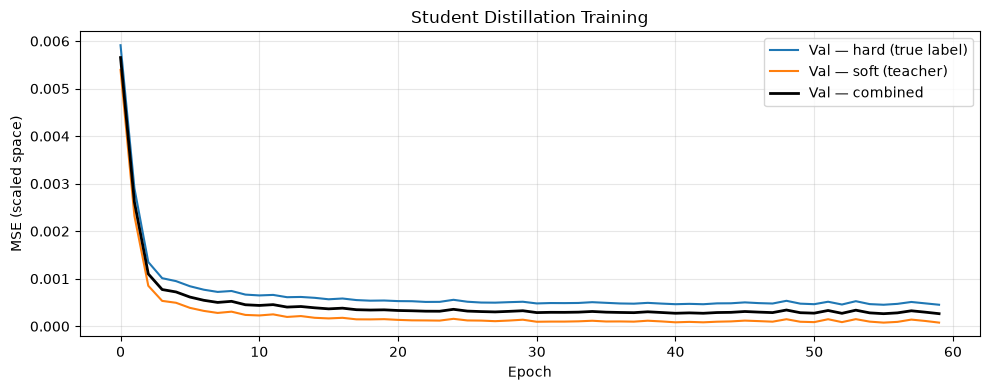

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history["val_hard"], label="Val — hard (true label)")
ax.plot(history["val_soft"], label="Val — soft (teacher)")
ax.plot(history["val_total"], label="Val — combined", linewidth=2, color="black")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE (scaled space)")
ax.set_title("Student Distillation Training")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DATA / "distillation_loss.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
np.save(DATA / "preds_student_test_mw.npy",  student_test_mw)
np.save(DATA / "preds_student_test_scaled.npy", student_test_s)
np.save(DATA / "preds_teacher_test_mw.npy",  teacher_test_mw)

with open(DATA / "distillation_results.json", "w") as f:
    json.dump({
        "teacher_test":       results[0],
        "student_test":       results[1],
        "size_reduction_pct": reduction,
        "student_params":     student_params,
        "student_latency_ms": s_lat,
        "teacher_latency_ms": t_lat,
        "speedup_x":          t_lat / s_lat,
    }, f, indent=2)

print("Saved: student.pt, distillation_results.json, prediction arrays.")

Saved: student.pt, distillation_results.json, prediction arrays.
